In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("../Dataset/insurance.csv")
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:

print("Shape:", df.shape)
print("\nDataset Information:")
df.info()
df.describe()

Shape: (1338, 7)

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [3]:

print("Missing Values:")
print(df.isnull().sum())
print("\nNumber of Duplicate Rows:", df.duplicated().sum())
print("\nCategorical Column Values:")
for col in ['sex', 'smoker', 'region']:
    print(col, ":", df[col].unique())

Missing Values:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Number of Duplicate Rows: 1

Categorical Column Values:
sex : <StringArray>
['female', 'male']
Length: 2, dtype: str
smoker : <StringArray>
['yes', 'no']
Length: 2, dtype: str
region : <StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [4]:

df.drop_duplicates(inplace=True)
print("Dataset shape after cleaning:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Dataset shape after cleaning: (1337, 7)
Duplicate rows remaining: 0


C:\Users\Lenovo\AppData\Local\Temp\ipykernel_18564\767190578.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [5]:
df.to_csv("../Dataset/insurance_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [6]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../Dataset/insurance_cleaned.csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Dataset loaded successfully!
Shape: (1337, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [8]:
df.describe()

,age,bmi,children,charges
count,1337.000000,1337.000000,1337.000000,1337.000000
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.290000,0.000000,4746.344000
50%,39.000000,30.400000,1.000000,9386.161300
75%,51.000000,34.700000,2.000000,16657.717450
max,64.000000,53.130000,5.000000,63770.428010


In [9]:
print("Average Charges by Gender:")
print(df.groupby('sex')['charges'].mean())

print("\nAverage Charges by Smoking Status:")
print(df.groupby('smoker')['charges'].mean())

print("\nAverage Charges by Region:")
print(df.groupby('region')['charges'].mean())

Average Charges by Gender:
sex
female    12569.578844
male      13974.998864
Name: charges, dtype: float64

Average Charges by Smoking Status:
smoker
no      8440.660307
yes    32050.231832
Name: charges, dtype: float64

Average Charges by Region:
region
northeast    13406.384516
northwest    12450.840844
southeast    14735.411438
southwest    12346.937377
Name: charges, dtype: float64


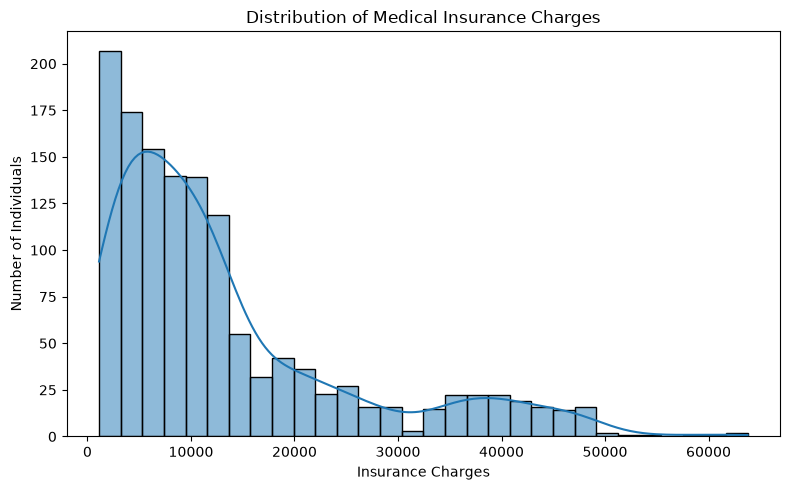

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='charges', bins=30, kde=True)

plt.title("Distribution of Medical Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Number of Individuals")

plt.tight_layout()
plt.savefig("../Images/charges_distribution.png")
plt.show()

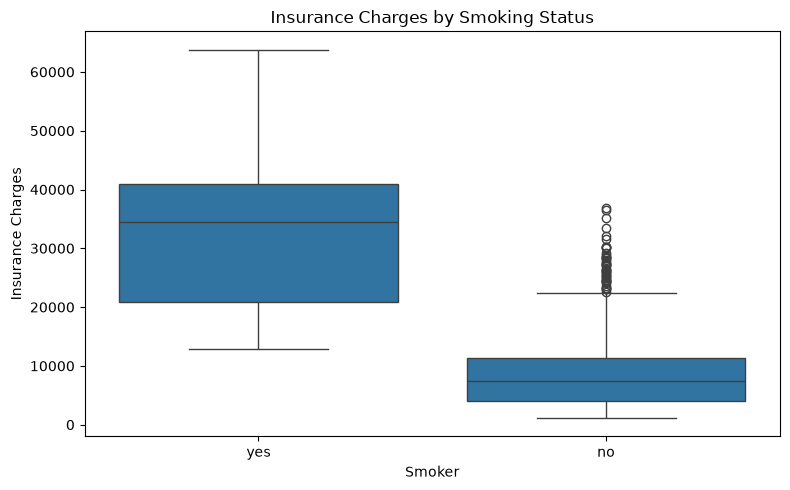

In [11]:
plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x='smoker', y='charges')

plt.title("Insurance Charges by Smoking Status")
plt.xlabel("Smoker")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.savefig("../Images/charges_by_smoker.png")
plt.show()

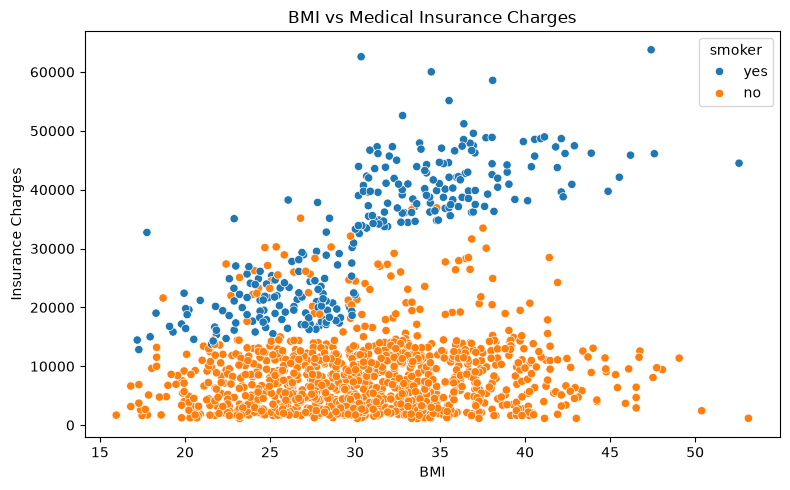

In [12]:
plt.figure(figsize=(8, 5))

sns.scatterplot(data=df, x='bmi', y='charges', hue='smoker')

plt.title("BMI vs Medical Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")

plt.tight_layout()
plt.savefig("../Images/bmi_vs_charges.png")
plt.show()

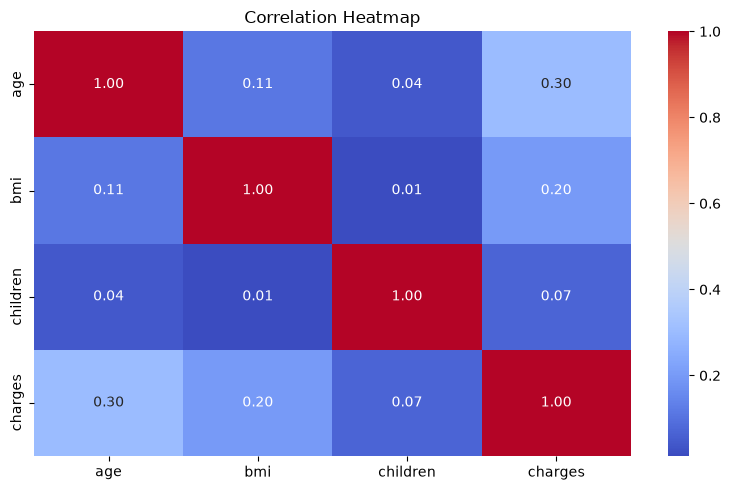

In [13]:
plt.figure(figsize=(8, 5))

sns.heatmap(
    df.select_dtypes(include='number').corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")

plt.tight_layout()
plt.savefig("../Images/correlation_heatmap.png")
plt.show()

In [14]:

print(df[['sex', 'smoker', 'region']].head())
print(df.dtypes)

      sex smoker     region
0  female    yes  southwest
1    male     no  southeast
2    male     no  southeast
3    male     no  northwest
4    male     no  northwest
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object


In [15]:

df_encoded = pd.get_dummies(
    df,
    columns=['sex', 'smoker', 'region'],
    drop_first=True,
    dtype=int
)
df_encoded.head()

,age,bmi,children,charges,sex_male,smoker_yes,region_northwest,region_southeast,region_southwest
0,19,27.900,0,16884.92400,0,1,0,0,1
1,18,33.770,1,1725.55230,1,0,0,1,0
2,28,33.000,3,4449.46200,1,0,0,1,0
3,33,22.705,0,21984.47061,1,0,1,0,0
4,32,28.880,0,3866.85520,1,0,1,0,0


In [16]:
print("New Dataset Shape:", df_encoded.shape)

print("\nUpdated Column Names:")
print(df_encoded.columns.tolist())

print("\nData Types:")
print(df_encoded.dtypes)

New Dataset Shape: (1337, 9)

Updated Column Names:
['age', 'bmi', 'children', 'charges', 'sex_male', 'smoker_yes', 'region_northwest', 'region_southeast', 'region_southwest']

Data Types:
age                   int64
bmi                 float64
children              int64
charges             float64
sex_male              int64
smoker_yes            int64
region_northwest      int64
region_southeast      int64
region_southwest      int64
dtype: object


In [17]:

X = df_encoded.drop('charges', axis=1)
y = df_encoded['charges']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (1337, 8)
Target (y) shape: (1337,)


In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (1069, 8)
Testing Features: (268, 8)
Training Target: (1069,)
Testing Target: (268,)


In [19]:
from sklearn.linear_model import LinearRegression
model = LinearRegression()
model.fit(X_train, y_train)
print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [20]:

y_pred = model.predict(X_test)
comparison = pd.DataFrame({
    'Actual Charges': y_test.values,
    'Predicted Charges': y_pred
})

comparison.head(10)

,Actual Charges,Predicted Charges
0,8688.85885,8143.693884
1,5708.86700,5737.115683
2,11436.73815,14369.314876
3,38746.35510,31745.513636
4,4463.20510,8962.386657
5,9304.70190,13149.722353
6,38511.62830,30446.760679
7,2150.46900,1453.288813
8,7345.72660,10633.018402
9,10264.44210,11318.943794


In [21]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("Model Evaluation Results")
print("------------------------")
print("R2 Score:", round(r2, 4))
print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))

Model Evaluation Results
------------------------
R2 Score: 0.8069
MAE: 4177.05
RMSE: 5956.34


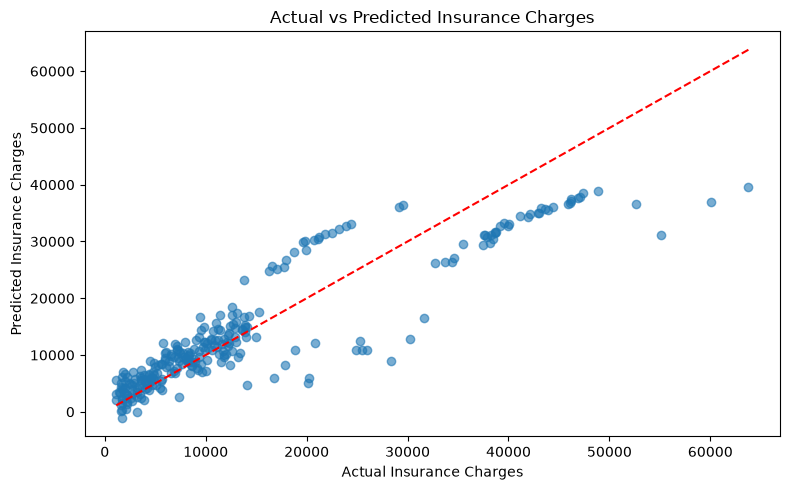

In [22]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.title("Actual vs Predicted Insurance Charges")

plt.tight_layout()
plt.savefig("../Images/actual_vs_predicted.png")
plt.show()

In [23]:
# Check minimum and maximum values
print("Age Range:")
print(df['age'].min(), "-", df['age'].max())

print("\nBMI Range:")
print(df['bmi'].min(), "-", df['bmi'].max())

print("\nInsurance Charges Range:")
print(df['charges'].min(), "-", df['charges'].max())

# Check for zero or negative values
print("\nNon-positive values:")
print((df[['age', 'bmi', 'charges']] <= 0).sum())

Age Range:
18 - 64

BMI Range:
15.96 - 53.13

Insurance Charges Range:
1121.8739 - 63770.42801

Non-positive values:
age        0
bmi        0
charges    0
dtype: int64


In [24]:

print("Age Range:")
print(df['age'].min(), "-", df['age'].max())

print("\nBMI Range:")
print(df['bmi'].min(), "-", df['bmi'].max())

print("\nInsurance Charges Range:")
print(df['charges'].min(), "-", df['charges'].max())

print("\nNon-positive values:")
print((df[['age', 'bmi', 'charges']] <= 0).sum())

Age Range:
18 - 64

BMI Range:
15.96 - 53.13

Insurance Charges Range:
1121.8739 - 63770.42801

Non-positive values:
age        0
bmi        0
charges    0
dtype: int64


In [25]:


categorical_columns = ['sex', 'smoker', 'region']

for col in categorical_columns:
    df[col] = df[col].str.strip().str.lower()


for col in categorical_columns:
    print(col, ":", df[col].unique())

sex : <StringArray>
['female', 'male']
Length: 2, dtype: str
smoker : <StringArray>
['yes', 'no']
Length: 2, dtype: str
region : <StringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


In [26]:

df.to_csv("../Dataset/insurance_cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")
print("Final dataset shape:", df.shape)

Cleaned dataset saved successfully!
Final dataset shape: (1337, 7)


In [27]:
from sklearn.inspection import permutation_importance

result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='r2'
)

importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': result.importances_mean
})

importance = importance.sort_values(
    by='Importance',
    ascending=False
)

print(importance.to_string(index=False))

         Feature  Importance
      smoker_yes    1.128267
             age    0.154160
             bmi    0.052462
        children    0.004695
region_southwest    0.002688
region_southeast    0.001955
        sex_male   -0.000009
region_northwest   -0.000377


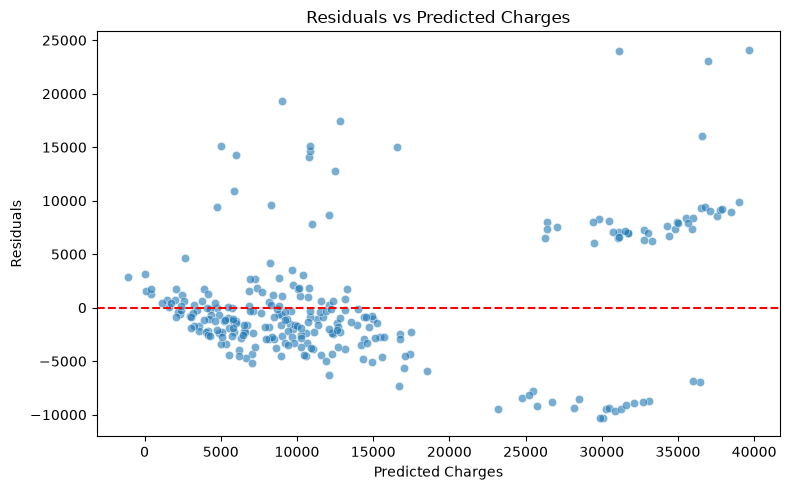

In [28]:

residuals = y_test - y_pred

plt.figure(figsize=(8, 5))

sns.scatterplot(
    x=y_pred,
    y=residuals,
    alpha=0.6
)

plt.axhline(y=0, color='red', linestyle='--')

plt.title("Residuals vs Predicted Charges")
plt.xlabel("Predicted Charges")
plt.ylabel("Residuals")

plt.tight_layout()
plt.savefig("../Images/residuals_vs_predicted.png")
plt.show()

In [30]:
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression

# Create polynomial features
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(),
    LinearRegression()
)

# Train model
poly_model.fit(X_train, y_train)

# Make predictions
y_pred_poly = poly_model.predict(X_test)

# Evaluate model
print("R2 Score:", r2_score(y_test, y_pred_poly))
print("MAE:", mean_absolute_error(y_test, y_pred_poly))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_poly)))

R2 Score: 0.8825298972468523
MAE: 2867.317439475324
RMSE: 4646.056793068929


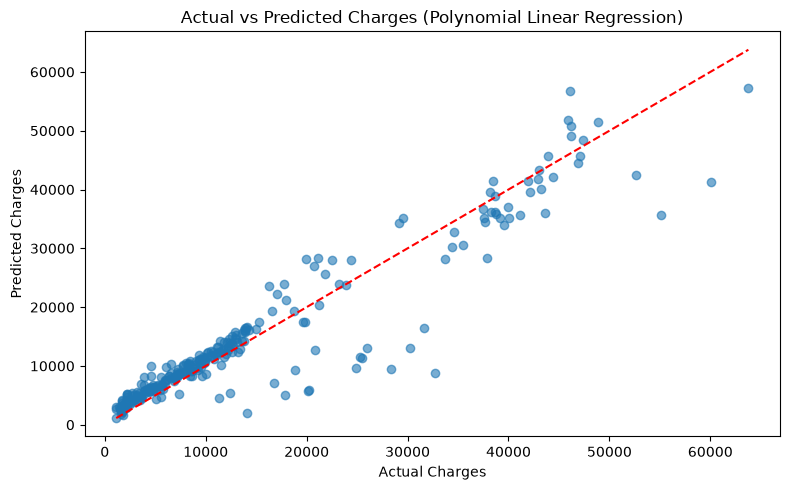

In [31]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_poly, alpha=0.6)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges (Polynomial Linear Regression)")

plt.tight_layout()
plt.savefig("../Images/polynomial_actual_vs_predicted.png")
plt.show()

In [32]:
from sklearn.inspection import permutation_importance

result_poly = permutation_importance(
    poly_model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='r2'
)

poly_importance = pd.DataFrame({
    'Feature': X_test.columns,
    'Importance': result_poly.importances_mean
})

poly_importance = poly_importance.sort_values(
    by='Importance',
    ascending=False
)

print(poly_importance.to_string(index=False))

         Feature  Importance
      smoker_yes    1.342751
             bmi    0.205853
             age    0.155482
        children    0.010852
region_southeast    0.007186
region_southwest    0.006807
        sex_male   -0.000494
region_northwest   -0.002852
